# Real-Time Fraud Detection Pipeline — Unified Team Starter Notebook (ICFD-31k)
**Review 2 Deliverable | Shared Data Download, EDA, Data Cleaning, Feature Engineering, PCA & Evaluation Framework**

### Why Everyone Starts With This Exact Notebook
To ensure a **100% fair, apples-to-apples benchmark** across all four team members, every member runs Sections 0–6 identically (producing the exact same cleaned, scaled, **PCA-reduced 40-feature matrices**), and then implements their assigned anomaly detection algorithm in **Section 7 (Model Implementation Zone)** at the bottom:

| Team Member | Assigned Model (Section 7) | Primary Metric |
| :--- | :--- | :--- |
| **Hemanth M**  | Deep Autoencoder (PyTorch) + Final Comparison | F1-Score (ROC-AUC, PR-AUC, TTD) |
| **Harshini D** | Kernel One-Class SVM (RBF / Nyström) | F1-Score (ROC-AUC, PR-AUC, TTD) |
| **Harsh Yadav** | Shrinkage Mahalanobis Distance (Ledoit-Wolf) | F1-Score (ROC-AUC, PR-AUC, TTD) |
| **Harshitha R** | Isolation Forest (Baseline) | F1-Score (ROC-AUC, PR-AUC, TTD) |

### Pipeline Architecture Inside This Notebook
1. **Section 0:** Environment setup, GPU detection, and fixed `RANDOM_SEED = 42`.
2. **Section 1:** Idempotent download of `rishia2220/icfd-31k` from Hugging Face.
3. **Section 2:** Full shard stitching (`train`, `validation`, `test`) and chronological call sorting (`conversation_uid`, `chunk_timestamp`).
4. **Section 3:** Exploratory Data Analysis (EDA) + saved Slide 6 charts.
5. **Section 4:** Data Cleaning, Missing-Value Handling, Audio JSON Parsing & Strict Data-Leakage Removal.
6. **Section 5:** Multilingual English/Hinglish Sentence Embeddings (384-dim) + Audio/Time Features (~410 raw features) $
ightarrow$ `StandardScaler` $
ightarrow$ **PCA Dimensionality Reduction (`40` features, strictly $\le 50$)** fitted **only** on normal training calls.
7. **Section 6:** Standardized Validation Threshold Grid Search, Risk Velocity & Forward-Chaining Reasoning Engine (`NORMAL / REVIEW / ALERT`), and Evaluation Metrics Suite.
8. **Section 7:** **Teammate Model Implementation Zone** — plug in your assigned model here!

> **Colab Tip:** In Google Colab, go to **Runtime $
ightarrow$ Change runtime type $
ightarrow$ T4 GPU** before running so sentence embeddings finish in a few minutes instead of hours.

## Section 0: Environment Setup & Global Configuration
Installs required packages (if missing), sets `RANDOM_SEED = 42` for reproducibility, and configures paths so this notebook works identically on **Google Colab** and **local VS Code / Jupyter**.

In [22]:
# Install required libraries if running on a fresh Google Colab runtime
%pip install -q huggingface_hub pyarrow sentence-transformers scikit-learn matplotlib joblib tqdm

In [23]:
import gc
import json
import os
import random
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import torch
from huggingface_hub import snapshot_download
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ==============================================================================
# FIXED GLOBAL SETTINGS (DO NOT CHANGE — MUST BE IDENTICAL FOR ALL 4 TEAMMATES)
# ==============================================================================
RANDOM_SEED = 42
EMBEDDING_MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
PCA_N_COMPONENTS = 40          # Strictly <= 50 features as required by faculty
TOP_N_EMOTIONS = 12            # Keep top 12 emotions; group rare ones as 'Other'
EMBEDDING_BATCH_SIZE = 512     # Fast on Colab T4 GPU (automatically scales on CPU)

# Reproducibility
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Directory layout (works in Colab /content/ and local folders)
BASE_DIR = Path(".")
DATA_DIR = BASE_DIR / "data" / "icfd-31k"
FEATURE_DIR = BASE_DIR / "data" / "clean_features_pca40"
EDA_DIR = BASE_DIR / "outputs" / "eda"
MODEL_OUT_DIR = BASE_DIR / "outputs" / "models"

for d in [DATA_DIR, FEATURE_DIR, EDA_DIR, MODEL_OUT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print(f"Compute Device     : {DEVICE.upper()}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else " (WARNING: Switch Colab to T4 GPU for fast embeddings!)"))
print(f"Random Seed        : {RANDOM_SEED}")
print(f"Embedding Model    : {EMBEDDING_MODEL_NAME}")
print(f"Target PCA Dims    : {PCA_N_COMPONENTS} (<= 50)")
print(f"Dataset Directory  : {DATA_DIR.resolve()}")
print(f"Feature Cache Dir  : {FEATURE_DIR.resolve()}")

Compute Device     : CUDA (Tesla T4)
Random Seed        : 42
Embedding Model    : sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Target PCA Dims    : 40 (<= 50)
Dataset Directory  : /content/data/icfd-31k
Feature Cache Dir  : /content/data/clean_features_pca40


## Section 1: Download ICFD-31k Dataset from Hugging Face
Downloads `rishia2220/icfd-31k` (~61.66 MB) once. If already downloaded, it skips straight to loading `release_summary.json`.

In [24]:
summary_file = DATA_DIR / "release_summary.json"

if not summary_file.exists():
    print("Downloading ICFD-31k from Hugging Face (rishia2220/icfd-31k)...")
    snapshot_download(
        repo_id="rishia2220/icfd-31k",
        repo_type="dataset",
        local_dir=str(DATA_DIR),
    )
    print("Download complete.")
else:
    print(f"Dataset already present at: {DATA_DIR.resolve()}")

with open(summary_file, "r", encoding="utf-8") as f:
    release_summary = json.load(f)

print("\nOfficial Release Summary:")
print(json.dumps(release_summary, indent=2))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 88 files:   0%|          | 0/88 [00:00<?, ?it/s]

Download complete.

Official Release Summary:
{
  "cross_domain_batches": {
    "batch_2025-10-15_04-59-55": "cross_domain_1",
    "batch_2025-10-15_05-02-25": "cross_domain_2",
    "batch_2025-10-15_05-04-26": "cross_domain_3",
    "batch_2025-10-15_05-06-26": "cross_domain_4",
    "batch_2025-10-15_05-08-27": "cross_domain_5"
  },
  "dataset": "ICFD-31k",
  "main_batch_domains": {
    "batch_2025-10-11_21-42-13": "bank_payment_fraud",
    "batch_2025-10-12_19-54-00": "ecommerce_marketplace",
    "batch_2025-10-12_22-36-40": "utility_bill_service",
    "batch_2025-10-12_23-39-07": "job_employment",
    "batch_2025-10-13_00-20-15": "loan_shark_harassment",
    "batch_2025-10-13_01-02-16": "tech_support_account",
    "batch_2025-10-13_01-36-50": "personal_emergency_extortion",
    "batch_2025-10-13_02-01-52": "insurance_healthcare",
    "batch_2025-10-13_02-35-27": "travel_lottery",
    "batch_2025-10-13_02-53-33": "government_impersonation"
  },
  "source_counts": {
    "cross_domain":

## Section 2: Stitch All Shards Per Split & Sort Calls Chronologically
Because individual `.parquet` shards split conversations across file borders, we load **all shards** of each split (`train`, `validation`, `test`) together via `pyarrow.parquet`, keeping only the 7 columns required for EDA, feature extraction, and held-out evaluation (which saves >60% RAM and avoids Python 3.14 `ArrowKeyError`).

> **Strict Leakage Rule:** `conversation_uid`, `domain`, `case_type`, and `final_verdict` are loaded **only** for EDA, grouping, and evaluation — they are **never** fed into any model's input matrix `X`.

In [25]:
# Load only necessary columns to keep RAM well under Colab's 12.7 GB limit
LOAD_COLS = [
    "conversation_uid",
    "domain",
    "case_type",
    "final_verdict",
    "chunk_timestamp",
    "cumulative_text",
    "cumulative_audio_analysis_json",
]

# Explicit Leakage / Metadata Columns (NEVER fed to model X)
LEAKAGE_AND_META_COLS = [
    "conversation_uid",
    "domain",
    "case_type",
    "final_verdict",
]

# Safe Raw Feature Columns (ONLY these 3 are transformed into model X)
SAFE_FEATURE_COLS = [
    "cumulative_text",
    "cumulative_audio_analysis_json",
    "chunk_timestamp",
]

def load_stitched_split(split_name: str):
    """Load all parquet shards for a split, stitch split calls together,
    sort chronologically, and return (DataFrame, call_index_map)."""
    shard_files = sorted((DATA_DIR / "streaming_chunks").glob(f"{split_name}-*.parquet"))
    if not shard_files:
        raise FileNotFoundError(f"No parquet shards found for '{split_name}' in {DATA_DIR / 'streaming_chunks'}")

    df = pq.read_table(shard_files, columns=LOAD_COLS).to_pandas()
    df = df.sort_values(["conversation_uid", "chunk_timestamp"]).reset_index(drop=True)

    call_map = {
        uid: grp.index.to_numpy()
        for uid, grp in df.groupby("conversation_uid", sort=False)
    }
    return df, call_map

train_df, train_calls = load_stitched_split("train")
val_df, val_calls     = load_stitched_split("validation")
test_df, test_calls   = load_stitched_split("test")

splits = {
    "train": (train_df, train_calls),
    "validation": (val_df, val_calls),
    "test": (test_df, test_calls),
}

print(f"{'Split':<12} | {'Calls':>8} | {'Chunks':>10} | {'Avg Chunks/Call':>15} | {'RAM (MB)':>10}")
print("-" * 66)
for name, (df, cmap) in splits.items():
    ram_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
    print(f"{name:<12} | {len(cmap):>8,} | {len(df):>10,} | {len(df)/len(cmap):>15.2f} | {ram_mb:>10.1f}")

Split        |    Calls |     Chunks | Avg Chunks/Call |   RAM (MB)
------------------------------------------------------------------
train        |   20,996 |    712,316 |           33.93 |      945.1
validation   |    4,499 |    173,813 |           38.63 |      252.2
test         |    4,499 |    179,827 |           39.97 |      251.8


## Section 3: Exploratory Data Analysis (EDA) & Data Integrity Audit
Before cleaning or modeling, we verify:
1. **Zero Session Overlap:** No `conversation_uid` appears in more than one split.
2. **Call-Level & Chunk-Level Class Balance:** Fraud (`YES`) vs. Legitimate (`NO`) counts across splits.
3. **10-Domain Distribution & Call Duration Distributions.**
4. **Presentation-Ready EDA Charts** saved to `./outputs/eda/`.

In [26]:
# 1. Cross-split session overlap audit
overlap_tv = set(train_calls.keys()) & set(val_calls.keys())
overlap_tt = set(train_calls.keys()) & set(test_calls.keys())
overlap_vt = set(val_calls.keys()) & set(test_calls.keys())
assert len(overlap_tv) == 0 and len(overlap_tt) == 0 and len(overlap_vt) == 0, "Data leakage: overlapping calls found!"
print("PASS: 0 overlapping conversation_uid values across train, validation, and test splits.")

# 2. Call-level summary helper
def summarize_calls(df):
    return (
        df.groupby("conversation_uid", sort=False)
        .agg(
            domain=("domain", "first"),
            case_type=("case_type", "first"),
            final_verdict=("final_verdict", "last"),
            num_chunks=("chunk_timestamp", "size"),
            first_ts=("chunk_timestamp", "min"),
            last_ts=("chunk_timestamp", "max"),
        )
        .reset_index()
    )

call_summaries = {name: summarize_calls(df) for name, (df, _) in splits.items()}
train_call_summary = call_summaries["train"]

verdict_table = pd.DataFrame(
    {name: cs["final_verdict"].value_counts() for name, cs in call_summaries.items()}
).fillna(0).astype(int)
verdict_table["Total"] = verdict_table.sum(axis=1)

print("\n=== Call-Level Verdict Distribution Across Splits ===")
print(verdict_table)

print("\n=== Train Call Duration & Chunk Summary ===")
print(train_call_summary[["num_chunks", "first_ts", "last_ts"]].describe().round(2))

print("\n=== Train Domain Breakdown (Call Level) ===")
domain_ct = pd.crosstab(train_call_summary["domain"], train_call_summary["final_verdict"])
domain_ct["Total"] = domain_ct.sum(axis=1)
if "YES" in domain_ct.columns:
    domain_ct["Fraud_%"] = (domain_ct["YES"] / domain_ct["Total"] * 100).round(1)
print(domain_ct.sort_values("Total", ascending=False))

# Missing values check before cleaning
print("\n=== Raw Missing Values in Train Split ===")
print(train_df.isnull().sum())

PASS: 0 overlapping conversation_uid values across train, validation, and test splits.

=== Call-Level Verdict Distribution Across Splits ===
               train  validation  test  Total
final_verdict                                
NO             15178          49    49  15276
YES             5818        4450  4450  14718

=== Train Call Duration & Chunk Summary ===
       num_chunks  first_ts   last_ts
count    20996.00  20996.00  20996.00
mean        33.93      8.71    107.49
std         17.06      2.99     52.15
min          5.00      3.00     18.00
25%         22.00      6.00     69.00
50%         30.00      6.00     96.00
75%         41.00     12.00    129.00
max        118.00     12.00    360.00

=== Train Domain Breakdown (Call Level) ===
final_verdict                   NO  YES  Total  Fraud_%
domain                                                 
bank_payment_fraud            1500  600   2100     28.6
ecommerce_marketplace         1511  589   2100     28.0
government_imperso

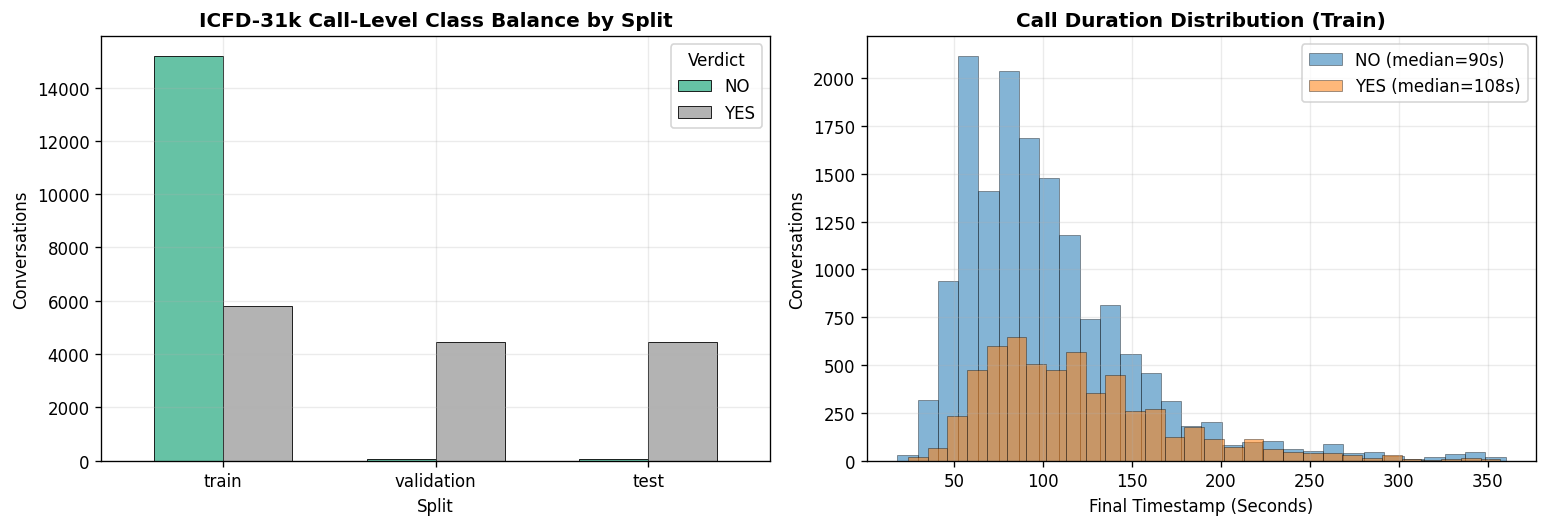

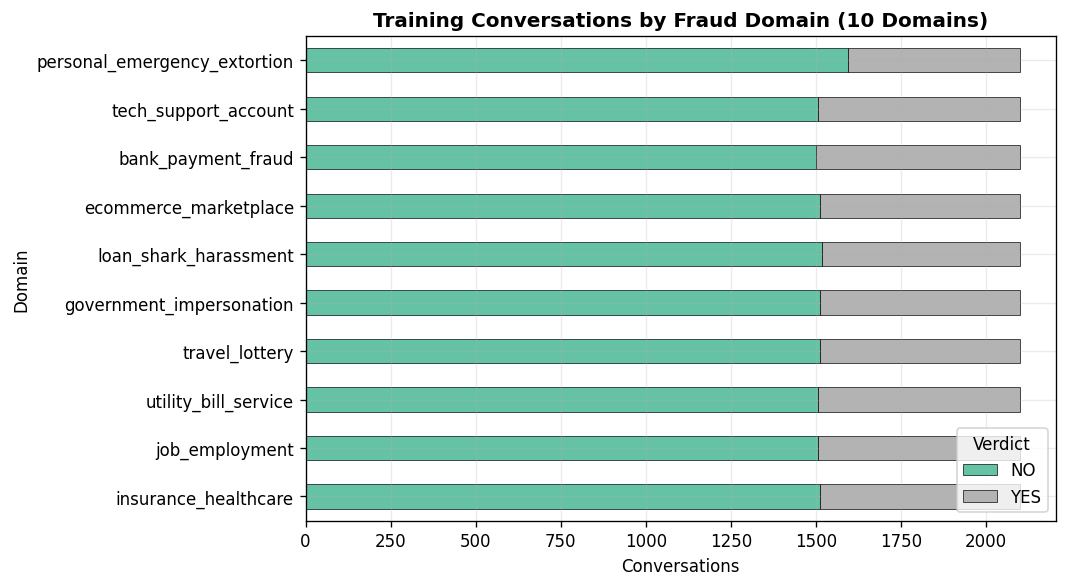

In [27]:
# Generate and save core EDA plots
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot 1: Call-Level Class Balance Across Splits
verdict_table.drop(columns=["Total"]).T.plot(
    kind="bar", ax=axes[0], width=0.65, colormap="Set2", edgecolor="black", linewidth=0.5
)
axes[0].set_title("ICFD-31k Call-Level Class Balance by Split", fontweight="bold")
axes[0].set_xlabel("Split")
axes[0].set_ylabel("Conversations")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Verdict")

# Plot 2: Call Duration Distribution (Train)
for v in sorted(train_call_summary["final_verdict"].dropna().unique()):
    sub = train_call_summary.loc[train_call_summary["final_verdict"] == v, "last_ts"]
    axes[1].hist(sub, bins=30, alpha=0.55, label=f"{v} (median={sub.median():.0f}s)", edgecolor="black", linewidth=0.4)
axes[1].set_title("Call Duration Distribution (Train)", fontweight="bold")
axes[1].set_xlabel("Final Timestamp (Seconds)")
axes[1].set_ylabel("Conversations")
axes[1].legend()

plt.tight_layout()
fig.savefig(EDA_DIR / "01_eda_splits_and_durations.png", dpi=200)
plt.show()

# Plot 3: 10 Fraud Domains (Train)
fig, ax = plt.subplots(figsize=(9, 5))
dom_cols = [c for c in domain_ct.columns if c not in ("Total", "Fraud_%")]
domain_ct[dom_cols].loc[domain_ct.sort_values("Total").index].plot(
    kind="barh", stacked=True, ax=ax, colormap="Set2", edgecolor="black", linewidth=0.4
)
ax.set_title("Training Conversations by Fraud Domain (10 Domains)", fontweight="bold")
ax.set_xlabel("Conversations")
ax.set_ylabel("Domain")
ax.legend(title="Verdict", loc="lower right")
plt.tight_layout()
fig.savefig(EDA_DIR / "02_eda_domain_breakdown.png", dpi=200)
plt.show()

## Section 4: Data Cleaning, Audio JSON Parsing & Normal-Only Split
This section performs strict, leakage-free data cleaning across `train`, `validation`, and `test`:
1. **Standardize Verdict Labels:** Strips whitespace/casing and creates binary ground-truth arrays `y` (`1` = Fraud `YES`, `0` = Legitimate `NO`) kept strictly separate from features.
2. **Clean Transcript Text:** Replaces nulls with `""`, normalizes whitespace/newlines, and drops empty-text rows from training.
3. **Parse `cumulative_audio_analysis_json` Safely:** Extracts `dominant_emotion`, `secondary_emotion`, `pace` (mapped to ordinal `Slow=0, Medium=1, Fast=2`), and numeric `confidence_score`. Missing numeric values are imputed using **only the normal-training median**.
4. **Filter Training Set to Normal Calls Only (`train_normal`):** Unsupervised anomaly detectors learn *only* legitimate behaviour (`final_verdict == "NO"`). We also drop consecutive identical-text pause rows from `train_normal` so silence does not bias the models, while keeping `validation` and `test` **100% intact** for realistic 3-second streaming evaluation.

In [28]:
PACE_MAP = {"slow": 0.0, "medium": 1.0, "fast": 2.0}

def safe_parse_audio_json(val):
    if isinstance(val, dict):
        return val
    if pd.isna(val):
        return {}
    s = str(val).strip()
    if not s:
        return {}
    try:
        return json.loads(s)
    except json.JSONDecodeError:
        return {}

def clean_dataframe(df: pd.DataFrame, is_train_normal: bool = False) -> pd.DataFrame:
    """Clean text, timestamps, labels, and parse cumulative_audio_analysis_json."""
    out = df.copy()

    # 1. Clean ground-truth verdict -> binary label (for evaluation/filtering ONLY)
    out["final_verdict"] = out["final_verdict"].fillna("NO").astype(str).str.strip().str.upper()
    out["y_label"] = (out["final_verdict"] == "YES").astype(np.int8)

    # 2. Clean cumulative_text (remove nulls, normalize whitespace/newlines)
    out["clean_text"] = (
        out["cumulative_text"]
        .fillna("")
        .astype(str)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    # 3. Clean chunk_timestamp
    out["chunk_timestamp"] = pd.to_numeric(out["chunk_timestamp"], errors="coerce").fillna(0.0).clip(lower=0.0).astype(np.float32)

    # 4. Parse cumulative_audio_analysis_json safely
    parsed = [safe_parse_audio_json(x) for x in out["cumulative_audio_analysis_json"]]
    audio_df = pd.DataFrame(parsed)

    dom_emo = audio_df["dominant_emotion"] if "dominant_emotion" in audio_df.columns else pd.Series("Unknown", index=out.index)
    sec_emo = audio_df["secondary_emotion"] if "secondary_emotion" in audio_df.columns else pd.Series("Unknown", index=out.index)
    pace_raw = audio_df["pace"] if "pace" in audio_df.columns else pd.Series(np.nan, index=out.index)
    conf_raw = audio_df["confidence_score"] if "confidence_score" in audio_df.columns else pd.Series(np.nan, index=out.index)

    out["dominant_emotion"] = dom_emo.fillna("Unknown").astype(str).str.strip().replace("", "Unknown")
    out["secondary_emotion"] = sec_emo.fillna("Unknown").astype(str).str.strip().replace("", "Unknown")
    out["pace_num"] = pace_raw.astype(str).str.strip().str.lower().map(PACE_MAP).astype(np.float32)
    out["confidence_score"] = pd.to_numeric(conf_raw, errors="coerce").clip(0.0, 1.0).astype(np.float32)

    # Drop raw uncleaned text/JSON columns to free memory
    out = out.drop(columns=["cumulative_text", "cumulative_audio_analysis_json"])

    # 5. For normal training set ONLY: keep legitimate calls, drop empty texts & consecutive identical silence chunks
    if is_train_normal:
        before = len(out)
        out = out[out["y_label"] == 0].reset_index(drop=True)
        normal_count = len(out)
        out = out[out["clean_text"].str.len() > 0].reset_index(drop=True)
        same_call = out["conversation_uid"] == out["conversation_uid"].shift(1)
        same_text = out["clean_text"] == out["clean_text"].shift(1)
        out = out[~(same_call & same_text)].reset_index(drop=True)
        print(
            f"[Train Normal Cleaning] Raw: {before:,} -> Normal (NO): {normal_count:,} "
            f"-> After removing empty & duplicate pause chunks: {len(out):,}"
        )
    return out

train_normal_clean = clean_dataframe(train_df, is_train_normal=True)
val_clean          = clean_dataframe(val_df, is_train_normal=False)
test_clean         = clean_dataframe(test_df, is_train_normal=False)

# Fit missing-value medians and top-emotion vocabulary ONLY on train_normal_clean (zero leakage!)
PACE_MEDIAN = float(train_normal_clean["pace_num"].median()) if not train_normal_clean["pace_num"].isna().all() else 1.0
CONF_MEDIAN = float(train_normal_clean["confidence_score"].median()) if not train_normal_clean["confidence_score"].isna().all() else 1.0

TOP_DOM_EMOTIONS = set(train_normal_clean["dominant_emotion"].value_counts().head(TOP_N_EMOTIONS).index)
TOP_SEC_EMOTIONS = set(train_normal_clean["secondary_emotion"].value_counts().head(TOP_N_EMOTIONS).index)

for df_c in [train_normal_clean, val_clean, test_clean]:
    df_c["pace_num"] = df_c["pace_num"].fillna(PACE_MEDIAN).astype(np.float32)
    df_c["confidence_score"] = df_c["confidence_score"].fillna(CONF_MEDIAN).astype(np.float32)
    df_c["dominant_emotion"] = df_c["dominant_emotion"].where(df_c["dominant_emotion"].isin(TOP_DOM_EMOTIONS), "Other")
    df_c["secondary_emotion"] = df_c["secondary_emotion"].where(df_c["secondary_emotion"].isin(TOP_SEC_EMOTIONS), "Other")

# Free raw uncleaned DataFrames to keep Colab RAM low
del train_df, val_df, test_df, splits
gc.collect()

print(f"Cleaned Train Normal chunks : {len(train_normal_clean):,} (100% Legitimate)")
print(f"Cleaned Validation chunks   : {len(val_clean):,} (Fraud chunks: {val_clean['y_label'].sum():,})")
print(f"Cleaned Test chunks         : {len(test_clean):,} (Fraud chunks: {test_clean['y_label'].sum():,})")
print(f"Imputation Medians (from Train Normal) -> pace: {PACE_MEDIAN:.2f}, confidence: {CONF_MEDIAN:.3f}")

[Train Normal Cleaning] Raw: 712,316 -> Normal (NO): 563,251 -> After removing empty & duplicate pause chunks: 203,273
Cleaned Train Normal chunks : 203,273 (100% Legitimate)
Cleaned Validation chunks   : 173,813 (Fraud chunks: 114,301)
Cleaned Test chunks         : 179,827 (Fraud chunks: 115,157)
Imputation Medians (from Train Normal) -> pace: 1.00, confidence: 1.000


## Section 5: Feature Engineering, Scaling & PCA Dimensionality Reduction ($\le 50$ Features)
Converting our 3 safe inputs into numerical features creates **~410 raw features**:
* **384 features:** Multilingual English/Hinglish Sentence Embeddings (`paraphrase-multilingual-MiniLM-L12-v2`)
* **~24 features:** One-Hot Encoded `dominant_emotion` and `secondary_emotion`
* **3 features:** Ordinal `pace_num`, `confidence_score`, and `chunk_timestamp`

Because **~410 features > 50**, we apply **Principal Component Analysis (PCA)** to compress the scaled feature vector down to **`40` uncorrelated principal components** (`PCA_N_COMPONENTS = 40`):
* **Zero Data Leakage:** `OneHotEncoder`, `StandardScaler`, and `PCA` are **fitted ONLY on `train_normal`**, then applied via `.transform()` to `validation` and `test`.
* **Speed & Memory Optimization:** Identical `clean_text` strings within each split are encoded only once (deduplicated) in GPU FP16, and splits are transformed one-by-one so peak RAM stays under ~4 GB.
* **Automatic Caching:** Once generated, the clean `X_train_normal.npy`, `X_val.npy`, `X_test.npy` arrays are saved to `./data/clean_features_pca40/` so future runs load in 1 second.

In [29]:
cache_ready = all(
    (FEATURE_DIR / fname).exists()
    for fname in [
        "X_train_normal.npy", "X_val.npy", "X_test.npy",
        "y_val.npy", "y_test.npy",
        "val_meta.parquet", "test_meta.parquet",
        "preprocessing_artifacts.joblib",
    ]
)

if cache_ready:
    print("Found cached PCA-40 feature pack! Loading directly from disk...")
    X_train_normal = np.load(FEATURE_DIR / "X_train_normal.npy")
    X_val          = np.load(FEATURE_DIR / "X_val.npy")
    X_test         = np.load(FEATURE_DIR / "X_test.npy")
    y_val          = np.load(FEATURE_DIR / "y_val.npy")
    y_test         = np.load(FEATURE_DIR / "y_test.npy")
    val_meta       = pq.read_table(FEATURE_DIR / "val_meta.parquet").to_pandas()
    test_meta      = pq.read_table(FEATURE_DIR / "test_meta.parquet").to_pandas()
    artifacts      = joblib.load(FEATURE_DIR / "preprocessing_artifacts.joblib")
    pca            = artifacts["pca"]
    print("Loaded cached features successfully.")
else:
    t0 = time.time()
    print(f"Loading SentenceTransformer '{EMBEDDING_MODEL_NAME}' on {DEVICE.upper()}...")
    embedder = SentenceTransformer(EMBEDDING_MODEL_NAME, device=DEVICE)
    if DEVICE == "cuda":
        embedder.half()  # FP16 gives ~2x faster encoding on Colab T4 GPU

    def encode_texts_dedup(text_series: pd.Series, label: str) -> np.ndarray:
        """Encode unique texts once and map back to full split length (exact, faster)."""
        codes, uniques = pd.factorize(text_series, sort=False)
        unique_list = uniques.tolist()
        print(f"  Encoding {label}: {len(text_series):,} rows ({len(unique_list):,} unique texts)...")
        unique_embs = embedder.encode(
            unique_list,
            batch_size=EMBEDDING_BATCH_SIZE if DEVICE == "cuda" else 128,
            show_progress_bar=True,
            convert_to_numpy=True,
            normalize_embeddings=True,
        ).astype(np.float32)
        return unique_embs[codes]

    # Fit OneHotEncoder ONLY on train_normal emotions
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
    ohe.fit(train_normal_clean[["dominant_emotion", "secondary_emotion"]])

    def build_raw_matrix(df_c: pd.DataFrame, split_label: str) -> np.ndarray:
        emb = encode_texts_dedup(df_c["clean_text"], split_label)
        emo_ohe = ohe.transform(df_c[["dominant_emotion", "secondary_emotion"]]).astype(np.float32)
        num_feats = df_c[["pace_num", "confidence_score", "chunk_timestamp"]].to_numpy(dtype=np.float32)
        raw = np.hstack([emb, emo_ohe, num_feats]).astype(np.float32)
        del emb, emo_ohe, num_feats
        return raw

    # --- 1. Fit StandardScaler & PCA ONLY on Train Normal ---
    X_train_raw = build_raw_matrix(train_normal_clean, "train_normal")
    raw_dim = X_train_raw.shape[1]
    print(f"\nRaw combined feature dimension: {raw_dim} (> 50 -> applying PCA to {PCA_N_COMPONENTS} dims)")

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_raw).astype(np.float32)
    del X_train_raw
    gc.collect()

    n_comp = min(PCA_N_COMPONENTS, raw_dim)
    pca = PCA(n_components=n_comp, random_state=RANDOM_SEED)
    X_train_normal = pca.fit_transform(X_train_scaled).astype(np.float32)
    del X_train_scaled
    gc.collect()
    print(f"PCA fitted on train_normal -> Explained Variance ({n_comp} dims): {pca.explained_variance_ratio_.sum() * 100:.2f}%")

    # --- 2. Transform Validation Split ---
    X_val_raw = build_raw_matrix(val_clean, "validation")
    X_val = pca.transform(scaler.transform(X_val_raw)).astype(np.float32)
    del X_val_raw
    gc.collect()

    # --- 3. Transform Test Split ---
    X_test_raw = build_raw_matrix(test_clean, "test")
    X_test = pca.transform(scaler.transform(X_test_raw)).astype(np.float32)
    del X_test_raw
    gc.collect()

    # Release GPU memory from embedder
    del embedder
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

    # Prepare held-out labels & metadata (NEVER fed to model X)
    y_val  = val_clean["y_label"].to_numpy(dtype=np.int8)
    y_test = test_clean["y_label"].to_numpy(dtype=np.int8)
    META_COLS = ["conversation_uid", "domain", "case_type", "chunk_timestamp", "dominant_emotion", "pace_num", "y_label"]
    val_meta  = val_clean[META_COLS].reset_index(drop=True)
    test_meta = test_clean[META_COLS].reset_index(drop=True)

    # Save clean feature pack to disk
    np.save(FEATURE_DIR / "X_train_normal.npy", X_train_normal)
    np.save(FEATURE_DIR / "X_val.npy", X_val)
    np.save(FEATURE_DIR / "X_test.npy", X_test)
    np.save(FEATURE_DIR / "y_val.npy", y_val)
    np.save(FEATURE_DIR / "y_test.npy", y_test)
    pq.write_table(pa.Table.from_pandas(val_meta, preserve_index=False), FEATURE_DIR / "val_meta.parquet")
    pq.write_table(pa.Table.from_pandas(test_meta, preserve_index=False), FEATURE_DIR / "test_meta.parquet")
    joblib.dump(
        {"scaler": scaler, "pca": pca, "ohe": ohe, "pace_median": PACE_MEDIAN, "conf_median": CONF_MEDIAN, "raw_dim": raw_dim},
        FEATURE_DIR / "preprocessing_artifacts.joblib",
    )
    print(f"\nSaved clean PCA-{n_comp} feature pack to '{FEATURE_DIR.resolve()}' in {(time.time() - t0)/60:.2f} min.")

# Final verification of model-ready arrays
assert not np.isnan(X_train_normal).any(), "NaNs found in X_train_normal!"
assert not np.isnan(X_val).any(), "NaNs found in X_val!"
assert not np.isnan(X_test).any(), "NaNs found in X_test!"
assert X_train_normal.shape[1] <= 50, "Feature count exceeds 50!"

print("\n=== MODEL-READY FEATURE MATRICES VERIFIED ===")
print(f"X_train_normal : {X_train_normal.shape} ({X_train_normal.dtype}) — 0 NaNs")
print(f"X_val          : {X_val.shape} ({X_val.dtype}) | y_val fraud rate: {y_val.mean()*100:.2f}%")
print(f"X_test         : {X_test.shape} ({X_test.dtype}) | y_test fraud rate: {y_test.mean()*100:.2f}%")

Loading SentenceTransformer 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2' on CUDA...


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

... (11 outputs left out)

Batches:   0%|          | 0/117 [00:00<?, ?it/s]

  Encoding test: 179,827 rows (62,072 unique texts)...


Batches:   0%|          | 0/122 [00:00<?, ?it/s]


Saved clean PCA-40 feature pack to '/content/data/clean_features_pca40' in 6.17 min.

=== MODEL-READY FEATURE MATRICES VERIFIED ===
X_train_normal : (203273, 40) (float32) — 0 NaNs
X_val          : (173813, 40) (float32) | y_val fraud rate: 65.76%
X_test         : (179827, 40) (float32) | y_test fraud rate: 64.04%


In [ ]:
# Plot PCA Scree & Cumulative Explained Variance (for Review 2 presentation)
cum_var = np.cumsum(pca.explained_variance_ratio_) * 100
dims = np.arange(1, len(cum_var) + 1)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.bar(dims, pca.explained_variance_ratio_ * 100, alpha=0.55, label="Individual PC Variance (%)")
ax.plot(dims, cum_var, color="crimson", marker="o", markersize=3, linewidth=2, label=f"Cumulative Variance ({cum_var[-1]:.1f}% at {len(dims)} PCs)")
ax.set_title(f"PCA Dimensionality Reduction ({len(dims)} Components <= 50 Feature Limit)", fontweight="bold")
ax.set_xlabel("Principal Component")
ax.set_ylabel("Explained Variance (%)")
ax.legend(loc="center right")
plt.tight_layout()
fig.savefig(EDA_DIR / "03_pca_explained_variance.png", dpi=200)
plt.show()

## Section 6: Shared Threshold Calibration, Reasoning Engine & Evaluation Suite
**Every teammate MUST evaluate their model using these exact functions** so all 4 models are judged on the exact same criteria:
1. **`normalize_anomaly_scores()`** — Standardizes any model's raw anomaly score (where **higher = more anomalous**) using *only* `train_normal` percentiles (zero test leakage).
2. **`calibrate_thresholds_on_val()`** — Performs **Grid Search** on `validation` to find `tau_alert` (maximizing F1-score) and `tau_review` (early-warning threshold).
3. **`apply_reasoning_engine()`** — Computes **Risk Velocity** ($\Delta s_t = s_t - s_{t-1}$) per call and applies forward-chaining logic (`NORMAL` $\rightarrow$ `REVIEW` $\rightarrow$ `ALERT`) — directly satisfying Review 2's **Knowledge Representation & Reasoning** rubric.
4. **`evaluate_and_save_model()`** — Computes **Chunk-Level & Call-Level F1-Score (Primary Metric)**, Precision, Recall, FPR, ROC-AUC, PR-AUC, and **Median Time-to-Detection (TTD in seconds)**, and saves results + ROC/PR plots to `./outputs/models/`.

In [30]:
def normalize_anomaly_scores(train_raw: np.ndarray, val_raw: np.ndarray, test_raw: np.ndarray):
    """Robustly scale anomaly scores to ~[0, 1+] using ONLY train_normal statistics.
    IMPORTANT: Pass scores where HIGHER = MORE ANOMALOUS (e.g., negate sklearn decision_function)."""
    p5 = float(np.percentile(train_raw, 5))
    p95 = float(np.percentile(train_raw, 95))
    denom = max(p95 - p5, 1e-8)
    s_train = np.clip((train_raw - p5) / denom, 0.0, 5.0)
    s_val   = np.clip((val_raw - p5) / denom, 0.0, 5.0)
    s_test  = np.clip((test_raw - p5) / denom, 0.0, 5.0)
    return s_train, s_val, s_test


def calibrate_thresholds_on_val(val_scores: np.ndarray, y_val: np.ndarray):
    """Grid search on validation split to find optimal F1 alert threshold (tau_alert)
    and early-warning review threshold (tau_review)."""
    candidates = np.quantile(val_scores, np.linspace(0.05, 0.99, 180))
    best_f1, best_tau = -1.0, float(np.median(val_scores))
    for tau in candidates:
        preds = (val_scores >= tau).astype(np.int8)
        score = f1_score(y_val, preds, zero_division=0)
        if score > best_f1:
            best_f1 = float(score)
            best_tau = float(tau)
    tau_alert = best_tau
    tau_review = float(0.80 * tau_alert)
    tau_velocity = float(np.percentile(np.abs(np.diff(val_scores)), 95))
    print(f"[Validation Calibration] Best Val F1 = {best_f1:.4f} | tau_review = {tau_review:.4f} | tau_alert = {tau_alert:.4f} | tau_velocity = {tau_velocity:.4f}")
    return tau_review, tau_alert, tau_velocity


def apply_reasoning_engine(meta_df: pd.DataFrame, scores: np.ndarray, tau_review: float, tau_alert: float, tau_velocity: float) -> pd.DataFrame:
    """Forward-chaining rule-based reasoning engine over streaming session state:
    IF score >= tau_alert OR (score >= tau_review AND risk_velocity >= tau_velocity) -> ALERT
    ELSE IF score >= tau_review -> REVIEW
    ELSE -> NORMAL
    """
    res = meta_df[["conversation_uid", "domain", "chunk_timestamp", "dominant_emotion", "pace_num", "y_label"]].copy()
    res["anomaly_score"] = scores

    # Compute Risk Velocity (delta_s = s_t - s_{t-1}) within each conversation
    same_call = res["conversation_uid"] == res["conversation_uid"].shift(1)
    res["risk_velocity"] = np.where(same_call, res["anomaly_score"] - res["anomaly_score"].shift(1), 0.0)

    is_alert = (res["anomaly_score"] >= tau_alert) | (
        (res["anomaly_score"] >= tau_review) & (res["risk_velocity"] >= tau_velocity)
    )
    is_review = (~is_alert) & (res["anomaly_score"] >= tau_review)

    res["alert_level"] = np.where(is_alert, "ALERT", np.where(is_review, "REVIEW", "NORMAL"))
    res["pred_fraud"] = is_alert.astype(np.int8)
    return res


def evaluate_and_save_model(
    model_name: str,
    train_scores_raw: np.ndarray,
    val_scores_raw: np.ndarray,
    test_scores_raw: np.ndarray,
):
    """Full standardized evaluation on held-out test set (chunk-level + call-level + TTD)."""
    _, s_val, s_test = normalize_anomaly_scores(train_scores_raw, val_scores_raw, test_scores_raw)
    tau_review, tau_alert, tau_velocity = calibrate_thresholds_on_val(s_val, y_val)

    # Apply reasoning engine to test stream
    test_stream = apply_reasoning_engine(test_meta, s_test, tau_review, tau_alert, tau_velocity)

    # 1. Chunk-level metrics
    y_true_chunk = test_stream["y_label"].to_numpy()
    y_pred_chunk = test_stream["pred_fraud"].to_numpy()
    tn, fp, fn, tp = confusion_matrix(y_true_chunk, y_pred_chunk).ravel()
    chunk_metrics = {
        "chunk_f1": round(float(f1_score(y_true_chunk, y_pred_chunk, zero_division=0)), 4),
        "chunk_precision": round(float(precision_score(y_true_chunk, y_pred_chunk, zero_division=0)), 4),
        "chunk_recall": round(float(recall_score(y_true_chunk, y_pred_chunk, zero_division=0)), 4),
        "chunk_fpr": round(float(fp / max(fp + tn, 1)), 4),
        "chunk_roc_auc": round(float(roc_auc_score(y_true_chunk, s_test)), 4),
        "chunk_pr_auc": round(float(average_precision_score(y_true_chunk, s_test)), 4),
    }

    # 2. Call-level metrics (a call is flagged if any chunk triggers ALERT; call score = max chunk score)
    call_agg = (
        test_stream.groupby("conversation_uid", sort=False)
        .agg(
            y_true=("y_label", "last"),
            max_score=("anomaly_score", "max"),
            any_alert=("pred_fraud", "max"),
            call_duration=("chunk_timestamp", "max"),
        )
        .reset_index()
    )
    ctn, cfp, cfn, ctp = confusion_matrix(call_agg["y_true"], call_agg["any_alert"]).ravel()

    # 3. Median Time-to-Detection (TTD) on true fraud calls that were caught
    caught_fraud_chunks = test_stream[(test_stream["y_label"] == 1) & (test_stream["pred_fraud"] == 1)]
    first_alert_ts = caught_fraud_chunks.groupby("conversation_uid")["chunk_timestamp"].min()
    median_ttd_sec = round(float(first_alert_ts.median()), 2) if len(first_alert_ts) > 0 else None

    call_metrics = {
        "call_f1": round(float(f1_score(call_agg["y_true"], call_agg["any_alert"], zero_division=0)), 4),
        "call_precision": round(float(precision_score(call_agg["y_true"], call_agg["any_alert"], zero_division=0)), 4),
        "call_recall": round(float(recall_score(call_agg["y_true"], call_agg["any_alert"], zero_division=0)), 4),
        "call_fpr": round(float(cfp / max(cfp + ctn, 1)), 4),
        "call_roc_auc": round(float(roc_auc_score(call_agg["y_true"], call_agg["max_score"])), 4),
        "call_pr_auc": round(float(average_precision_score(call_agg["y_true"], call_agg["max_score"])), 4),
        "median_ttd_seconds": median_ttd_sec,
    }

    results = {
        "model_name": model_name,
        "pca_dimensions": int(X_train_normal.shape[1]),
        "thresholds": {"tau_review": round(tau_review, 4), "tau_alert": round(tau_alert, 4), "tau_velocity": round(tau_velocity, 4)},
        "chunk_level": chunk_metrics,
        "call_level": call_metrics,
    }

    print("\n" + "=" * 68)
    print(f"FINAL HELD-OUT TEST RESULTS — {model_name}")
    print("=" * 68)
    print(f"Chunk-Level -> F1: {chunk_metrics['chunk_f1']:.4f} | Prec: {chunk_metrics['chunk_precision']:.4f} | Rec: {chunk_metrics['chunk_recall']:.4f} | FPR: {chunk_metrics['chunk_fpr']:.4f} | ROC-AUC: {chunk_metrics['chunk_roc_auc']:.4f} | PR-AUC: {chunk_metrics['chunk_pr_auc']:.4f}")
    print(f"Call-Level  -> F1: {call_metrics['call_f1']:.4f} | Prec: {call_metrics['call_precision']:.4f} | Rec: {call_metrics['call_recall']:.4f} | FPR: {call_metrics['call_fpr']:.4f} | ROC-AUC: {call_metrics['call_roc_auc']:.4f} | PR-AUC: {call_metrics['call_pr_auc']:.4f}")
    print(f"Early Alert -> Median Time-to-Detection (Fraud Calls): {median_ttd_sec}s")
    print("=" * 68)

    # Save JSON + ROC/PR curves
    safe_slug = model_name.lower().replace(" ", "_")
    with open(MODEL_OUT_DIR / f"{safe_slug}_metrics.json", "w", encoding="utf-8") as f:
        json.dump(results, f, indent=2)

    fpr_curve, tpr_curve, _ = roc_curve(call_agg["y_true"], call_agg["max_score"])
    prec_curve, rec_curve, _ = precision_recall_curve(call_agg["y_true"], call_agg["max_score"])

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    axes[0].plot(fpr_curve, tpr_curve, linewidth=2, label=f"ROC-AUC = {call_metrics['call_roc_auc']:.4f}")
    axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
    axes[0].set_title(f"{model_name} — Call-Level ROC Curve", fontweight="bold")
    axes[0].set_xlabel("False Positive Rate")
    axes[0].set_ylabel("True Positive Rate")
    axes[0].legend()

    axes[1].plot(rec_curve, prec_curve, linewidth=2, color="darkorange", label=f"PR-AUC = {call_metrics['call_pr_auc']:.4f}")
    axes[1].set_title(f"{model_name} — Call-Level Precision-Recall Curve", fontweight="bold")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].legend()

    plt.tight_layout()
    fig.savefig(MODEL_OUT_DIR / f"{safe_slug}_curves.png", dpi=200)
    plt.show()

    return results, test_stream

## Section 7: Model Implementation Zone (Teammate Workspace)
Everything above this line is **100% shared and verified**. You now have the exact model-ready arrays in memory:
* **`X_train_normal`** — `(N_train_normal, 40)` float32, scaled & PCA-reduced (**normal calls only**)
* **`X_val`**, **`y_val`**, **`val_meta`** — held-out validation set (used for threshold calibration)
* **`X_test`**, **`y_test`**, **`test_meta`** — held-out test set (used for final unbiased evaluation)

### Instructions for Each Team Member
Implement **only your assigned model** in the cell below, compute raw anomaly scores where **HIGHER = MORE ANOMALOUS**, and pass them to `evaluate_and_save_model()`:

1. **Hemanth M — Deep Autoencoder (PyTorch):**
   * Train MLP Autoencoder (`40 -> 24 -> 12 -> 24 -> 40`) on `X_train_normal` using `MSELoss`.
   * Raw anomaly score = per-row Mean Squared Reconstruction Error `((X - X_hat) ** 2).mean(axis=1)`.
2. **Harshini D — Kernel One-Class SVM:**
   * Fit `OneClassSVM` (or `Nystroem(kernel='rbf') + SGDOneClassSVM` for fast scaling on full `X_train_normal`).
   * Raw anomaly score = **`-model.decision_function(X)`** *(negate so higher = more anomalous!)*.
3. **Harsh Yadav — Shrinkage Mahalanobis Distance:**
   * Fit `sklearn.covariance.LedoitWolf().fit(X_train_normal)`.
   * Raw anomaly score = `model.mahalanobis(X)`.
4. **Harshitha R — Isolation Forest (Baseline):**
   * Fit `sklearn.ensemble.IsolationForest(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1).fit(X_train_normal)`.
   * Raw anomaly score = **`-model.decision_function(X)`** *(negate so higher = more anomalous!)*.

Isolation Forest training completed!
Isolation Forest model saved successfully!
[Validation Calibration] Best Val F1 = 0.7799 | tau_review = 0.0022 | tau_alert = 0.0027 | tau_velocity = 0.1467

FINAL HELD-OUT TEST RESULTS — Isolation Forest
Chunk-Level -> F1: 0.7710 | Prec: 0.6431 | Rec: 0.9624 | FPR: 0.9510 | ROC-AUC: 0.5055 | PR-AUC: 0.6262
Call-Level  -> F1: 0.9932 | Prec: 0.9891 | Rec: 0.9973 | FPR: 1.0000 | ROC-AUC: 0.4229 | PR-AUC: 0.9843
Early Alert -> Median Time-to-Detection (Fraud Calls): 45.0s


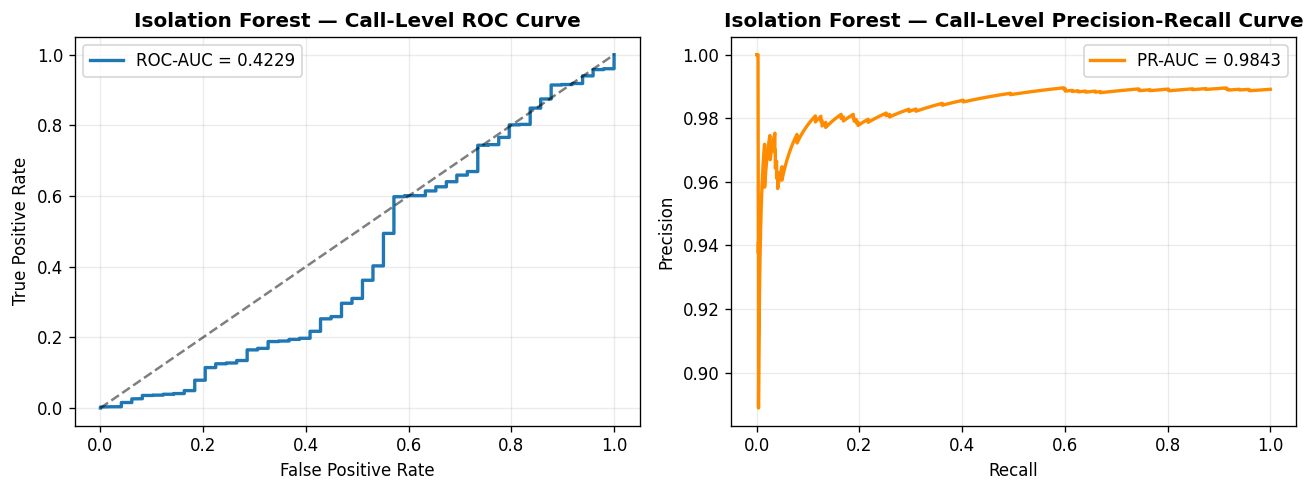

Isolation Forest evaluation completed!


In [31]:

# ==============================================================================
# SECTION 7: ISOLATION FOREST (BASELINE) - HARSHITHA R
# ==============================================================================

MODEL_NAME = "Isolation Forest"

from sklearn.ensemble import IsolationForest
import joblib

# 1. Create the Isolation Forest model
model = IsolationForest(
    n_estimators=200,
    random_state=RANDOM_SEED,
    n_jobs=-1
)

# 2. Train ONLY on normal training data
model.fit(X_train_normal)

print("Isolation Forest training completed!")

# 3. Calculate raw anomaly scores
# Higher score = More Anomalous

train_scores_raw = -model.decision_function(X_train_normal)
val_scores_raw = -model.decision_function(X_val)
test_scores_raw = -model.decision_function(X_test)

# 4. Save the trained model
joblib.dump(
    model,
    MODEL_OUT_DIR / "isolation_forest.joblib"
)

print("Isolation Forest model saved successfully!")

# 5. Run the built-in evaluator
results, test_stream_df = evaluate_and_save_model(
    model_name=MODEL_NAME,
    train_scores_raw=train_scores_raw,
    val_scores_raw=val_scores_raw,
    test_scores_raw=test_scores_raw,
)

print("Isolation Forest evaluation completed!")
